# 0. Data Understanding

Before cleaning and analyzing the data, we first need to understand the structure, content, and business meaning of the dataset.

The dataset contains sales transactions with information about customers, products, sales dates, quantities, prices, taxes, and profits.

The main objectives at this stage are to:

* Understand the dataset structure.
* Identify the meaning of the columns.
* Check the number of records and variables.
* Understand data types.
* Identify potential data quality issues.
* Define possible business questions for further analysis.

This step helps ensure that the cleaning and analysis process is based on an understanding of the business data rather than applying transformations blindly.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("dataset/FactSale.csv",encoding="latin1")

print("Dataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully.
Rows: 26397
Columns: 21


## 0.1 — Inspect Columns

In [2]:
print("Columns:")
print(df.columns.tolist())

Columns:
['Sale Key', 'City Key', 'Customer Key', 'Bill To Customer Key', 'Stock Item Key', 'Invoice Date Key', 'Delivery Date Key', 'Salesperson Key', 'WWI Invoice ID', 'Description', 'Package', 'Quantity', 'Unit Price', 'Tax Rate', 'Total Excluding Tax', 'Tax Amount', 'Profit', 'Total Including Tax', 'Total Dry Items', 'Total Chiller Items', 'Lineage Key']


## 0.2 — Inspect Sample Data

In [3]:
df.head()

,Sale Key,City Key,Customer Key,Bill To Customer Key,Stock Item Key,Invoice Date Key,Delivery Date Key,Salesperson Key,WWI Invoice ID,Description,...,Quantity,Unit Price,Tax Rate,Total Excluding Tax,Tax Amount,Profit,Total Including Tax,Total Dry Items,Total Chiller Items,Lineage Key
0,49265,41568,0,0,204,10/22/2013,10/23/2013,83,15189,DBA joke mug - mind if I join you? (White),...,6,13.0,15,78.0,11.7,51.0,89.7,6,0,11
1,49372,48937,0,0,173,10/22/2013,10/23/2013,83,15218,Developer joke mug - a foo walks into a bar (B...,...,6,13.0,15,78.0,11.7,51.0,89.7,6,0,11
2,50379,91464,0,0,174,10/28/2013,10/29/2013,70,15525,Developer joke mug - a foo walks into a bar (W...,...,6,13.0,15,78.0,11.7,51.0,89.7,6,0,11
3,51852,48937,0,0,171,11/6/2013,11/7/2013,74,15986,Developer joke mug - this code was generated b...,...,6,13.0,15,78.0,11.7,51.0,89.7,6,0,11
4,52374,89925,0,0,203,11/8/2013,11/9/2013,39,16138,DBA joke mug - mind if I join you? (Black),...,6,13.0,15,78.0,11.7,51.0,89.7,6,0,11


In [4]:
df.tail()

,Sale Key,City Key,Customer Key,Bill To Customer Key,Stock Item Key,Invoice Date Key,Delivery Date Key,Salesperson Key,WWI Invoice ID,Description,...,Quantity,Unit Price,Tax Rate,Total Excluding Tax,Tax Amount,Profit,Total Including Tax,Total Dry Items,Total Chiller Items,Lineage Key
26392,219912,108988,273,202,220,4/21/2016,4/22/2016,165,67945,Novelty chilli chocolates 500g,...,72,14.5,10,1044.0,104.4,414.0,1148.4,0,72,11
26393,220186,112229,0,0,220,4/22/2016,4/23/2016,171,68033,Novelty chilli chocolates 500g,...,12,14.5,10,174.0,17.4,69.0,191.4,0,12,11
26394,223515,112381,0,0,220,5/9/2016,5/10/2016,161,69055,Novelty chilli chocolates 500g,...,96,14.5,10,1392.0,139.2,552.0,1531.2,0,96,11
26395,224963,72760,23,1,220,5/14/2016,5/15/2016,170,69493,Novelty chilli chocolates 500g,...,12,14.5,10,174.0,17.4,69.0,191.4,0,12,11
26396,226629,66094,136,1,220,5/24/2016,5/25/2016,171,70005,Novelty chilli chocolates 500g,...,48,14.5,10,696.0,69.6,276.0,765.6,0,48,11


## 0.3 — Data Types

In [5]:
print(df.dtypes)

Sale Key                  int64
City Key                  int64
Customer Key              int64
Bill To Customer Key      int64
Stock Item Key            int64
Invoice Date Key         object
Delivery Date Key        object
Salesperson Key           int64
WWI Invoice ID            int64
Description              object
Package                  object
Quantity                  int64
Unit Price              float64
Tax Rate                  int64
Total Excluding Tax     float64
Tax Amount              float64
Profit                  float64
Total Including Tax     float64
Total Dry Items           int64
Total Chiller Items       int64
Lineage Key               int64
dtype: object


## 0.4 — Descriptive Statistics

In [6]:
df.describe()

,Sale Key,City Key,Customer Key,Bill To Customer Key,Stock Item Key,Salesperson Key,WWI Invoice ID,Quantity,Unit Price,Tax Rate,Total Excluding Tax,Tax Amount,Profit,Total Including Tax,Total Dry Items,Total Chiller Items,Lineage Key
count,26397.000000,26397.000000,26397.000000,26397.000000,26397.000000,26397.000000,26397.000000,26397.000000,26397.000000,26397.000000,26397.000000,26397.000000,26397.000000,26397.000000,26397.000000,26397.000000,26397.0
mean,113325.365079,72654.379248,111.540781,49.487934,111.130735,101.109785,34929.902262,38.969201,44.775579,14.978028,753.100458,112.720569,375.947710,865.821027,38.425503,0.543698,11.0
std,65852.471369,25386.126544,125.849109,86.398718,63.567575,46.422963,20323.753274,54.119390,135.170950,0.330730,1444.947561,216.671684,762.047362,1661.584982,53.702461,9.313398,0.0
min,2.000000,40550.000000,0.000000,0.000000,1.000000,4.000000,2.000000,1.000000,0.660000,10.000000,3.200000,0.480000,-645.000000,3.680000,0.000000,0.000000,11.0
25%,56575.000000,47673.000000,0.000000,0.000000,56.000000,72.000000,17418.000000,5.000000,13.000000,15.000000,96.000000,14.400000,50.400000,110.400000,5.000000,0.000000,11.0
50%,112395.000000,72709.000000,52.000000,1.000000,111.000000,105.000000,34613.000000,10.000000,18.000000,15.000000,226.800000,34.020000,120.000000,260.820000,9.000000,0.000000,11.0
75%,170972.000000,91372.000000,201.000000,1.000000,167.000000,143.000000,52699.000000,60.000000,32.000000,15.000000,864.000000,129.600000,390.000000,993.600000,60.000000,0.000000,11.0
max,228211.000000,115719.000000,399.000000,202.000000,227.000000,174.000000,70495.000000,360.000000,1899.000000,15.000000,18990.000000,2848.500000,9200.000000,21838.500000,360.000000,240.000000,11.0


## 0.5 — Understand Categorical Columns

In [7]:
print("Number of unique values:")
print(df.nunique().sort_values())

Number of unique values:
Lineage Key                 1
Tax Rate                    2
Bill To Customer Key        3
Package                     4
Total Chiller Items        15
Customer Key               49
Quantity                   61
Unit Price                 62
Total Dry Items            62
Salesperson Key            99
City Key                  153
Stock Item Key            227
Description               227
Total Excluding Tax       481
Tax Amount                483
Total Including Tax       486
Profit                    547
Delivery Date Key        1063
Invoice Date Key         1064
WWI Invoice ID           8188
Sale Key                26397
dtype: int64


* # Business Questions

After understanding the dataset, several business questions can be investigated:

1. What are the total sales and total profit?
2. How do sales and profit change over time?
3. Which products generate the highest sales?
4. Which products generate the highest profit?
5. Which customers generate the most revenue?
6. Which cities or regions generate the highest sales?
7. Which salespersons have the strongest performance?
8. Which package types are most frequently used?
9. Are there products or transactions generating negative profit?
10. How efficient is the delivery process?
11. Which periods have the highest and lowest sales?
12. Are there important differences between sales performance and profitability?

These questions will guide the cleaning, validation, analysis, and dashboard design.


# 1. Data Cleaning

The objective of this step is to identify and correct data quality issues before performing analysis.

The cleaning process includes:

* Handling missing values.
* Detecting duplicates.
* Correcting date formats.
* Converting columns to appropriate data types.
* Checking invalid or impossible values.
* Standardizing relevant fields.

All cleaning decisions will be documented to ensure that the final dataset remains reliable and suitable for analysis.


## 1.1 — Missing Values

In [11]:
missing_values = df.isnull().sum()

print("Missing values:")
print(missing_values[missing_values > 0])

Missing values:
Delivery Date Key    13
Delivery Days        13
dtype: int64


## 1.2 — Investigate Missing Dates

In [12]:
df[df["Delivery Date Key"].isnull()][
    [
        "Sale Key",
        "Invoice Date Key",
        "Description",
        "Quantity",
        "Unit Price",
        "Total Excluding Tax",
        "Profit"
    ]
]

,Sale Key,Invoice Date Key,Description,Quantity,Unit Price,Total Excluding Tax,Profit
23493,228211,2016-05-31,Plush shark slippers (Gray) M,10,32.00,320.0,240.0
23585,228210,2016-05-31,The Gu red shirt XML tag t-shirt (Black) L,48,18.00,864.0,528.0
23637,228112,2016-05-31,The Gu red shirt XML tag t-shirt (White) XL,120,18.00,2160.0,1260.0
23688,228114,2016-05-31,Superhero action jacket (Blue) XS,2,25.00,50.0,12.0
24111,228111,2016-05-31,Clear packaging tape 48mmx75m,208,2.90,603.2,249.6
24112,228113,2016-05-31,Bubblewrap dispenser (Red) 1.5m,7,240.00,1680.0,910.0
24113,228115,2016-05-31,Black and orange this way up despatch tape 48...,120,4.10,492.0,258.0
24746,228069,2016-05-31,Superhero action jacket (Blue) S,8,25.00,200.0,48.0
24988,228070,2016-05-31,Permanent marker red 5mm nib (Red) 5mm,108,2.70,291.6,108.0
24989,228071,2016-05-31,USB food flash drive - sushi roll,6,4.80,28.8,-43.2


## 1.3 — Fix Date Format

In [13]:
df["Invoice Date Key"] = pd.to_datetime(
    df["Invoice Date Key"],
    errors="coerce"
)

df["Delivery Date Key"] = pd.to_datetime(
    df["Delivery Date Key"],
    errors="coerce"
)

In [14]:
print(df[["Invoice Date Key", "Delivery Date Key"]].dtypes)

Invoice Date Key     datetime64[ns]
Delivery Date Key    datetime64[ns]
dtype: object


## 1.4 — Check Invalid Dates

In [15]:
print(
    "Invalid Invoice Dates:",
    df["Invoice Date Key"].isna().sum()
)

print(
    "Invalid Delivery Dates:",
    df["Delivery Date Key"].isna().sum()
)

Invalid Invoice Dates: 0
Invalid Delivery Dates: 13


## 1.5 — Investigate Delivery Date Logic

In [16]:
df["Delivery Days"] = (
    df["Delivery Date Key"] - df["Invoice Date Key"]
).dt.days

print(df["Delivery Days"].value_counts(dropna=False))
print("Missing Delivery Dates:", df["Delivery Date Key"].isna().sum())
print("Missing Delivery Days:", df["Delivery Days"].isna().sum())

Delivery Days
1.0    26384
NaN       13
Name: count, dtype: int64
Missing Delivery Dates: 13
Missing Delivery Days: 13


In [17]:
df[df["Delivery Days"].isna()][
    ["Invoice Date Key", "Delivery Date Key", "Delivery Days"]
]

,Invoice Date Key,Delivery Date Key,Delivery Days
23493,2016-05-31,NaT,NaN
23585,2016-05-31,NaT,NaN
23637,2016-05-31,NaT,NaN
23688,2016-05-31,NaT,NaN
24111,2016-05-31,NaT,NaN
24112,2016-05-31,NaT,NaN
24113,2016-05-31,NaT,NaN
24746,2016-05-31,NaT,NaN
24988,2016-05-31,NaT,NaN
24989,2016-05-31,NaT,NaN


## 1.6 — Handle Missing Delivery Dates

## Handle Missing Delivery Dates

The dataset contains **13 missing Delivery Dates**.

After reviewing the available records, all **26,384 valid delivery records** show a delivery time of exactly **one day after the invoice date**.

However, the actual delivery dates for the 13 missing records cannot be verified from the available data. Therefore, these values were **not imputed** based only on the observed pattern.

The missing values are retained as missing (`NaT`) to avoid introducing unsupported assumptions into the dataset.

## 1.7 — Check Duplicates

In [18]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


No duplicate rows were found

## 1.8 — Check Duplicate Sale Keys

In [19]:
print("Unique Sale Keys:", df["Sale Key"].nunique())
print("Total rows:", len(df))

print(
    "Duplicate Sale Keys:",
    df["Sale Key"].duplicated().sum()
)

Unique Sale Keys: 26397
Total rows: 26397
Duplicate Sale Keys: 0


## 1.9 — Check Numeric Values

In [20]:
print("Invalid Quantity:",
      (df["Quantity"] <= 0).sum())

print("Invalid Unit Price:",
      (df["Unit Price"] <= 0).sum())

print("Invalid Sales:",
      (df["Total Excluding Tax"] <= 0).sum())

Invalid Quantity: 0
Invalid Unit Price: 0
Invalid Sales: 0


## 1.10 — Final Data Cleaning Check

In [21]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Dataset shape: (26397, 22)

Missing values:
26

Duplicate rows:
0

Data types:
Sale Key                         int64
City Key                         int64
Customer Key                     int64
Bill To Customer Key             int64
Stock Item Key                   int64
Invoice Date Key        datetime64[ns]
Delivery Date Key       datetime64[ns]
Salesperson Key                  int64
WWI Invoice ID                   int64
Description                     object
Package                         object
Quantity                         int64
Unit Price                     float64
Tax Rate                         int64
Total Excluding Tax            float64
Tax Amount                     float64
Profit                         float64
Total Including Tax            float64
Total Dry Items                  int64
Total Chiller Items              int64
Lineage Key                      int64
Delivery Days                  float64
dtype: object


# 2. Data Validation

The objective of this step is to verify that the values and calculations in the dataset are logically consistent.

The validation process checks:

* Sales calculations.
* Tax calculations.
* Total amounts.
* Date relationships.
* Quantity and price validity.
* Profit values.
* Other business inconsistencies.

Any detected issue will be investigated and documented rather than automatically removed.


## 2.1 — Validate Sales Calculation

In [22]:
# Quantity × Unit Price = Total Excluding Tax
calculated_sales = (
    df["Quantity"] *
    df["Unit Price"]
)

sales_difference = (
    calculated_sales -
    df["Total Excluding Tax"]
).abs()

print(
    "Sales calculation errors:",
    (sales_difference > 0.01).sum()
)

Sales calculation errors: 0


## 2.2 — Validate Tax

In [23]:
#Tax Amount =Total Excluding Tax × Tax Rate / 100
calculated_tax = (
    df["Total Excluding Tax"] *
    df["Tax Rate"] / 100
)

tax_difference = (
    calculated_tax -
    df["Tax Amount"]
).abs()

print(
    "Tax calculation errors:",
    (tax_difference > 0.01).sum()
)

Tax calculation errors: 0


## 2.3 — Validate Total Including Tax

In [24]:
#Total Including Tax =Total Excluding Tax + Tax Amount
calculated_total = (
    df["Total Excluding Tax"] +
    df["Tax Amount"]
)

total_difference = (
    calculated_total -
    df["Total Including Tax"]
).abs()

print(
    "Total calculation errors:",
    (total_difference > 0.01).sum()
)

Total calculation errors: 0


## 2.4 — Validate Dates

In [25]:
#Delivery Date >= Invoice Date
invalid_delivery_dates = (
    df["Delivery Date Key"] <
    df["Invoice Date Key"]
)

print(
    "Delivery dates before invoice dates:",
    invalid_delivery_dates.sum()
)

Delivery dates before invoice dates: 0


## 2.5 — Validate Tax Rates

In [26]:
print(df["Tax Rate"].value_counts().sort_index())

Tax Rate
10      116
15    26281
Name: count, dtype: int64


## 2.6 — Negative Profit Investigation

In [27]:
negative_profit = df[df["Profit"] < 0]

print(
    "Negative profit records:",
    len(negative_profit)
)

negative_profit.head()

Negative profit records: 566


,Sale Key,City Key,Customer Key,Bill To Customer Key,Stock Item Key,Invoice Date Key,Delivery Date Key,Salesperson Key,WWI Invoice ID,Description,...,Unit Price,Tax Rate,Total Excluding Tax,Tax Amount,Profit,Total Including Tax,Total Dry Items,Total Chiller Items,Lineage Key,Delivery Days
216,59580,41568,0,0,78,2013-12-24,2013-12-25,83,18352,Halloween zombie mask (Light Brown) S,...,18.0,15,864.0,129.6,-48.0,993.6,48,0,11,1.0
219,52848,48851,0,0,78,2013-11-13,2013-11-14,91,16277,Halloween zombie mask (Light Brown) S,...,18.0,15,1296.0,194.4,-72.0,1490.4,72,0,11,1.0
220,53266,48762,0,0,78,2013-11-14,2013-11-15,19,16398,Halloween zombie mask (Light Brown) S,...,18.0,15,1296.0,194.4,-72.0,1490.4,72,0,11,1.0
241,50103,72709,0,0,75,2013-10-25,2013-10-26,85,15438,Halloween zombie mask (Light Brown) XL,...,18.0,15,432.0,64.8,-24.0,496.8,24,0,11,1.0
243,50888,72709,0,0,77,2013-10-30,2013-10-31,70,15686,Halloween zombie mask (Light Brown) M,...,18.0,15,2160.0,324.0,-120.0,2484.0,120,0,11,1.0


In [28]:
negative_profit[
    [
        "Sale Key",
        "Description",
        "Quantity",
        "Unit Price",
        "Total Excluding Tax",
        "Profit"
    ]
].head(20)

,Sale Key,Description,Quantity,Unit Price,Total Excluding Tax,Profit
216,59580,Halloween zombie mask (Light Brown) S,48,18.0,864.0,-48.0
219,52848,Halloween zombie mask (Light Brown) S,72,18.0,1296.0,-72.0
220,53266,Halloween zombie mask (Light Brown) S,72,18.0,1296.0,-72.0
241,50103,Halloween zombie mask (Light Brown) XL,24,18.0,432.0,-24.0
243,50888,Halloween zombie mask (Light Brown) M,120,18.0,2160.0,-120.0
245,51066,Halloween zombie mask (Light Brown) M,12,18.0,216.0,-12.0
256,53691,Halloween zombie mask (Light Brown) S,120,18.0,2160.0,-120.0
269,57019,Halloween zombie mask (Light Brown) L,84,18.0,1512.0,-84.0
276,59264,Halloween zombie mask (Light Brown) S,60,18.0,1080.0,-60.0
993,50620,Halloween zombie mask (Light Brown) XL,120,18.0,2160.0,-120.0


# 3. Exploratory Data Analysis

After completing the data cleaning and validation processes, exploratory data analysis is performed to understand the main business patterns in the dataset.

The objective of this step is to identify important trends and relationships that can support the selection of KPIs and visualizations for the management dashboard.

The analysis focuses on overall sales and profitability, time trends, product performance, customer performance, salesperson performance, package types, and negative-profit transactions.


## 3.1 Overall Business Performance

In [35]:
total_sales = df["Total Excluding Tax"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()
total_transactions = df["Sale Key"].nunique()

profit_margin = (total_profit / total_sales) * 100

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Profit Margin:", round(profit_margin, 2), "%")
print("Total Quantity:", total_quantity)
print("Total Transactions:", total_transactions)

Total Sales: 19879592.8
Total Profit: 9923891.7
Profit Margin: 49.92 %
Total Quantity: 1028670
Total Transactions: 26397


## 3.2 Sales Trend

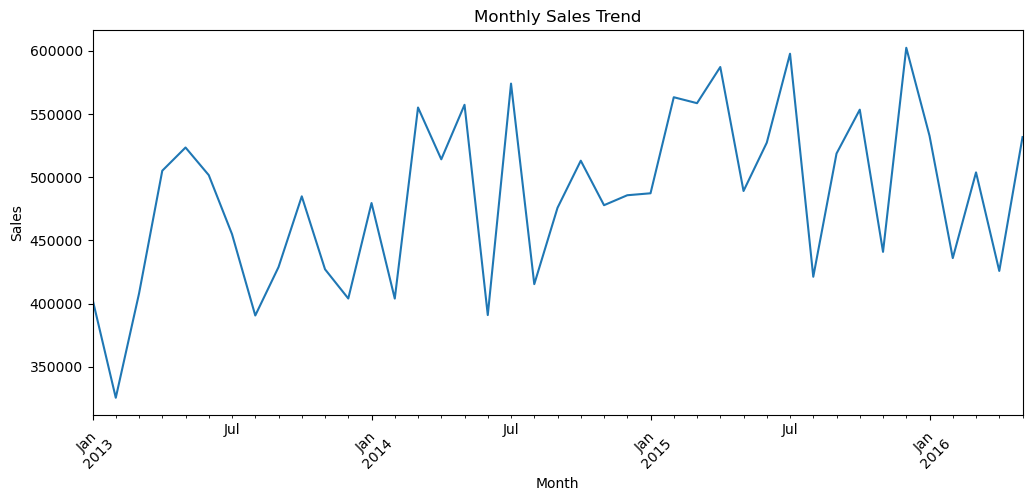

In [29]:
df["Year-Month"] = df["Invoice Date Key"].dt.to_period("M")

monthly_sales = (
    df.groupby("Year-Month")["Total Excluding Tax"]
      .sum()
)

monthly_sales.plot(figsize=(12,5))

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.show()

### Sales Trend Findings

- Monthly sales show noticeable fluctuations throughout the period.
- Sales generally reached higher levels during 2014 and 2015 compared with the beginning of 2013.
- The highest monthly sales were approximately $600K.
- Despite the overall stronger performance in later periods, sales remained volatile from month to month.

## 3.3 Monthly Profit

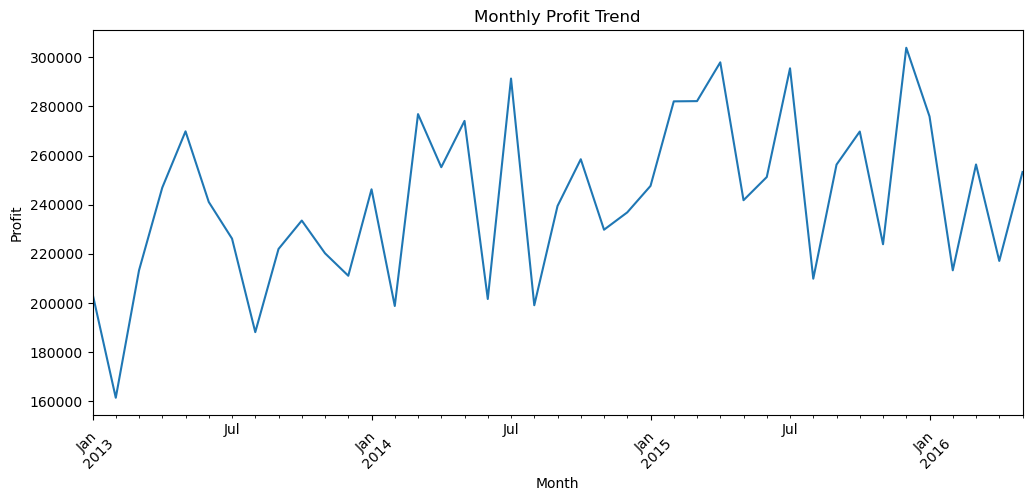

In [30]:
monthly_profit = (
    df.groupby("Year-Month")["Profit"]
      .sum()
)

monthly_profit.plot(figsize=(12,5))

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit")
plt.xticks(rotation=45)
plt.show()

## 3.4 Product Analysis

In [32]:
top_products_sales = (
    df.groupby("Description")["Total Excluding Tax"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

top_products_sales

Description
Air cushion machine (Blue)                  1198269.0
10 mm Anti static bubble wrap (Blue) 50m     866250.0
20 mm Double sided bubble wrap 50m           790560.0
32 mm Double sided bubble wrap 50m           769440.0
32 mm Anti static bubble wrap (Blue) 50m     631050.0
10 mm Double sided bubble wrap 50m           605850.0
20 mm Anti static bubble wrap (Blue) 50m     587520.0
Void fill 400 L bag (White) 400L             405500.0
32 mm Anti static bubble wrap (Blue) 20m     360000.0
20 mm Anti static bubble wrap (Blue) 20m     309600.0
Name: Total Excluding Tax, dtype: float64

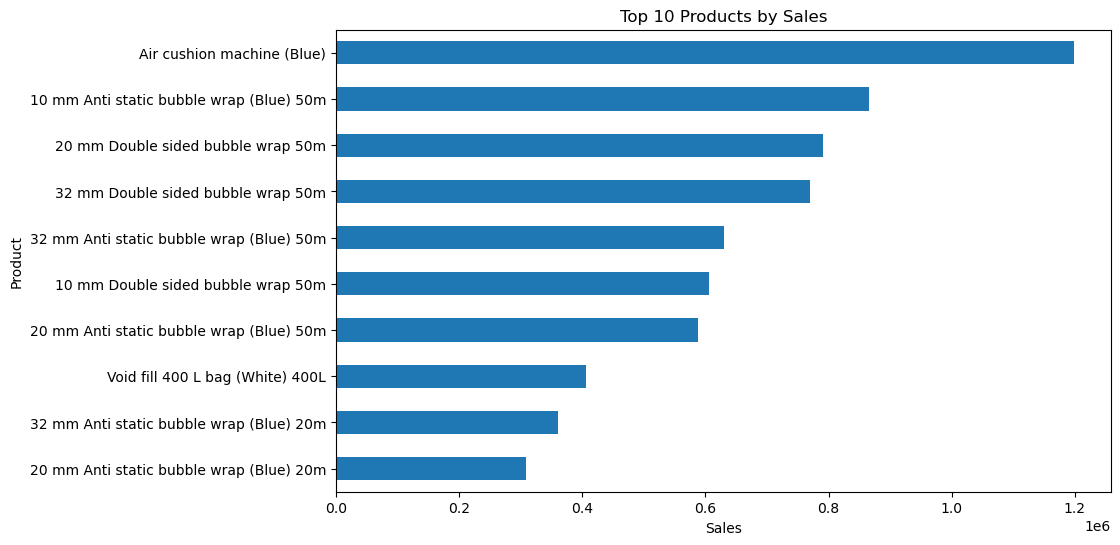

In [33]:
top_products_sales.sort_values().plot(
    kind="barh",
    figsize=(10,6)
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Sales")
plt.ylabel("Product")
plt.show()

## 3.5 Top Products by Profit

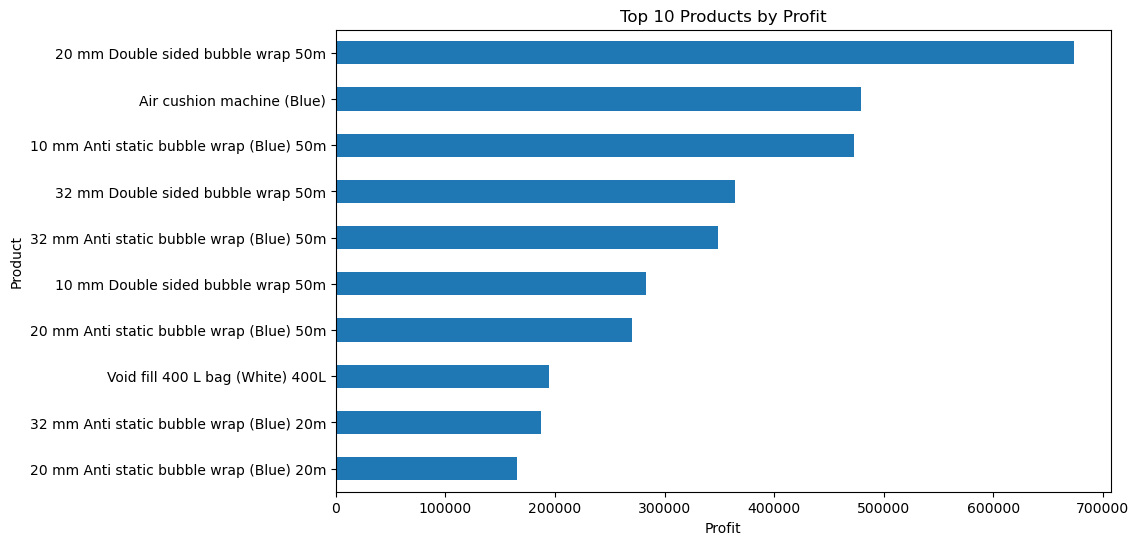

In [40]:
top_products_profit = (
    df.groupby("Description")["Profit"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

top_products_profit.sort_values().plot(
    kind="barh",
    figsize=(10,6)
)

plt.title("Top 10 Products by Profit")
plt.xlabel("Profit")
plt.ylabel("Product")
plt.show()

## 3.6 Customer Analysis

In [41]:
top_customers = (
    df.groupby("Customer Key")
      .agg(
          Sales=("Total Excluding Tax", "sum"),
          Profit=("Profit", "sum")
      )
      .sort_values("Sales", ascending=False)
      .head(10)
)

top_customers

,Sales,Profit
Customer Key,,
0,6768715.70,3428606.80
273,355293.35,185158.65
102,344005.05,163720.60
281,343236.10,163084.60
398,328237.65,167999.45
384,327417.20,161495.30
186,321476.10,156166.05
399,316857.85,161952.00
78,314765.10,155986.45


## 3.7 Salesperson Analysis

In [42]:
top_salespersons = (
    df.groupby("Salesperson Key")
      .agg(
          Sales=("Total Excluding Tax", "sum"),
          Profit=("Profit", "sum")
      )
      .sort_values("Sales", ascending=False)
      .head(10)
)

top_salespersons

,Sales,Profit
Salesperson Key,,
19,2005033.50,1010010.10
143,825195.75,412208.75
129,765170.55,375785.75
119,725206.40,360395.70
108,672605.00,344131.70
90,609464.85,303816.95
152,571889.75,276255.95
93,561964.25,276868.05
81,513180.65,247767.70


## 3.8 Package Analysis

In [43]:
package_analysis = (
    df.groupby("Package")
      .agg(
          Sales=("Total Excluding Tax", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
      .sort_values("Sales", ascending=False)
)

package_analysis

,Sales,Profit,Quantity
Package,,,
Each,19240949.2,9540374.1,979338
Packet,351648.0,216372.0,3408
Pair,157860.0,110502.0,31572
Bag,129135.6,56643.6,14352


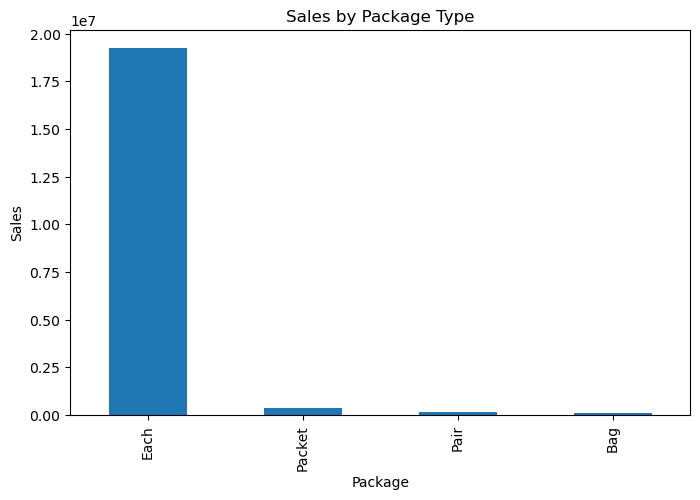

In [44]:
package_analysis["Sales"].plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Sales by Package Type")
plt.xlabel("Package")
plt.ylabel("Sales")
plt.show()

## 3.9 Negative Profit Analysis

In [45]:
negative_profit = df[df["Profit"] < 0]

negative_profit_by_product = (
    negative_profit
    .groupby("Description")
    .agg(
        Transactions=("Sale Key", "count"),
        Total_Loss=("Profit", "sum")
    )
    .sort_values("Total_Loss")
    .head(10)
)

negative_profit_by_product

,Transactions,Total_Loss
Description,,
Halloween zombie mask (Light Brown) M,131,-9024.0
Halloween zombie mask (Light Brown) S,126,-8904.0
Halloween zombie mask (Light Brown) XL,118,-7884.0
Halloween zombie mask (Light Brown) L,117,-7248.0
USB food flash drive - dim sum 10 drive variety pack,9,-3211.5
USB food flash drive - dessert 10 drive variety pack,3,-1590.0
USB food flash drive - chocolate bar,10,-439.2
USB food flash drive - hot dog,8,-380.0
USB missile launcher (Green),6,-273.5


In [34]:
df_cleaned = df.copy()

print("Cleaned dataset shape:", df_cleaned.shape)

Cleaned dataset shape: (26397, 23)


In [35]:
df_cleaned.to_csv(
    "dataset/sales_data_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.
